# Task 0: Power as a polynomial of speed and flow (Case 1)

**Owner:** Seb

Use Linear Regression to predict the power **P** from n (in krpm) and Q:

$$P = \sum_{i=0}^{3}\sum_{j=0}^{3} \alpha_{ij}\, n^i Q^j$$

Apply a **feature selection** method to find which terms belong in the formula. Train on train1, test on test1, report the final expression and the test errors, and plot the errors vs flow.

In [86]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import cross_val_score
import sympy as sp

import sys
sys.path.append("..")
from src.data import load_case1

In [87]:
#Data naming and cleaning. 
df_train, df_test  =load_case1()
n_train, n_test = df_train["speed_rpm"] / 1000, df_test["speed_rpm"] / 100   #now in kilo-rotations/minute!
Q_train, Q_test = np.array(df_train["flow_m3_h"]), np.array(df_test["flow_m3_h"])
y_train, y_test = np.array(df_train["power_w"]), np.array(df_test["power_w"]) #target variable

In [88]:
#From the given polynomial equation, design matrix X will have 16 featuers (cycling through both sum signs)

n , Q = sp.symbols("n, Q")

design_matrix = []

for i in range(4):
    for j in range(4):
        design_matrix.append(n**i * Q**j)

print("Design matrix in symbolic notation: \n", design_matrix)

Design matrix in symbolic notation: 
 [1, Q, Q**2, Q**3, n, Q*n, Q**2*n, Q**3*n, n**2, Q*n**2, Q**2*n**2, Q**3*n**2, n**3, Q*n**3, Q**2*n**3, Q**3*n**3]


In [89]:
#Now we fill in the design matrix with data

X_trainlist, X_testlist = [], []
index = 0

for i in range(4):
    for j in range(4):
        X_trainlist.append(n_train**i * Q_train**j)
        X_testlist.append(n_test**i * Q_test**j)

X_train = np.array(X_trainlist).T
X_test = np.array(X_testlist).T


C:\Users\Sebastian Nguyen\AppData\Local\Temp\ipykernel_344\1846348574.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Text(0.5, 1.0, 'Backward Feature Selection and \n Averaged Negative Mean Squared Error from 5-fold Cross-Validation')

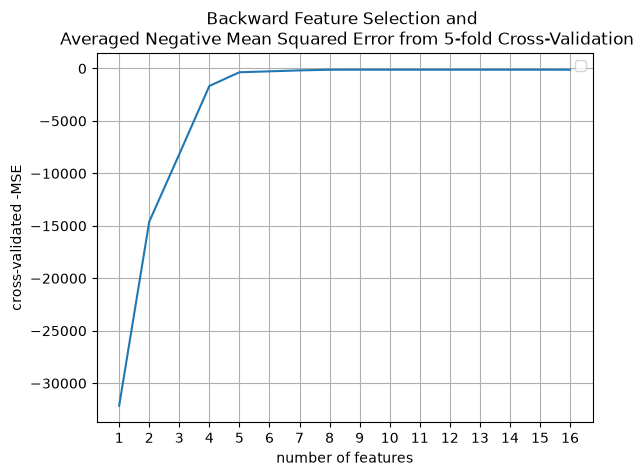

In [90]:
#Testing performance of different models from backward selection

#SequentialFeatureSelector only allows features_to_select to be less than n_features. So we make a model with all features after this loop.
no_fts = np.arange(1,16) 
model = LinearRegression()
cv_mse = []
for i in no_fts:
    sfs = SequentialFeatureSelector(model, direction = "backward", cv = 5, n_features_to_select= i)
    sfs.fit(X_train, y_train)
    selected_X_train = sfs.transform(X_train) #only relevent features selected

    #getting cross validation score

    scores = cross_val_score(LinearRegression(), selected_X_train, y_train, cv = 5, scoring="neg_mean_squared_error") #will output 5 scores, one for each iteration
    cv_mse.append(sum(scores)/5) #we choose to plot to mean of the five scores


#adding final model with all features
scores = cross_val_score(LinearRegression(), X_train, y_train, cv = 5, scoring= "neg_mean_squared_error") #will output 5 scores, one for each iteration
cv_mse.append(sum(scores)/5) #we choose to plot to mean of the five scores

no_fts = np.arange(1,17) 
plt.plot(no_fts, cv_mse)


plt.xlabel("number of features")
plt.ylabel("cross-validated -MSE")
plt.legend()
plt.grid()
plt.xticks(no_fts)
plt.title("Backward Feature Selection and \n Averaged Negative Mean Squared Error from 5-fold Cross-Validation")

In [91]:
#Hm, it seems like we can choose 4 features if the value is less than 1/2 st dev away from 5 features.

st_dev = np.std(cv_mse)
mean = np.mean(cv_mse)

stds = abs(cv_mse[4]-cv_mse[3])/st_dev 
print("number of standard deveations between 4 and 5 features models: ", stds)

#We can choose 4 features!

number of standard deveations between 4 and 5 features models:  0.15778123062459337


In [92]:
sfs = SequentialFeatureSelector(model, direction = "backward", cv = 5, n_features_to_select= 4)
sfs.fit(X_train, y_train)

X_train_selected = sfs.transform(X_train)
X_test_selected = sfs.transform(X_test)
best_model = LinearRegression().fit(X_train_selected, y_train)

print("Selected features: ")
for i in np.argwhere(sfs.get_support() ==True).flatten():
    print (design_matrix[i])
print("\n")
print("Coefficients: ", best_model.coef_)

y_pred = best_model.predict(X_test_selected)
print("train MSE score for selected model: ", mean_squared_error(y_train, best_model.predict(X_train_selected)))
print("test MSE for selected model: ", mean_squared_error(y_test, best_model.predict(X_test_selected)))

Selected features: 
Q*n
Q**2*n
Q**2*n**2
n**3


Coefficients:  [12.36186374 -0.48277995  0.06948715  8.91915894]
train MSE score for selected model:  1466.3754781424261
test MSE for selected model:  270180528216.3349


Now we try the same for forward selection:

C:\Users\Sebastian Nguyen\AppData\Local\Temp\ipykernel_344\3637856334.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


Text(0.5, 1.0, 'Forward Feature Selection and \n Averaged Negative Mean Squared Error from 5-fold Cross-Validation')

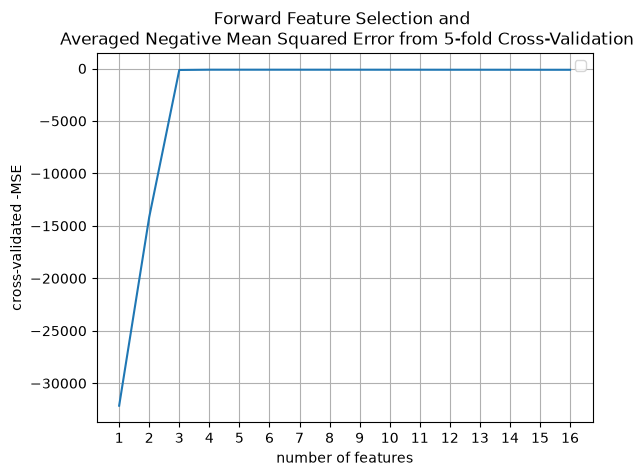

In [93]:
#Testing performance of different models from forward selection

#SequentialFeatureSelector only allows features_to_select to be less than n_features. So we make a model with all features after this loop.
no_fts = np.arange(1,16) 
model = LinearRegression()
cv_mse = []
for i in no_fts:
    sfs = SequentialFeatureSelector(model, direction = "forward", cv = 5, n_features_to_select= i)
    sfs.fit(X_train, y_train)
    selected_X_train = sfs.transform(X_train) #only relevent features selected

    #getting cross validation score

    scores = cross_val_score(LinearRegression(), selected_X_train, y_train, cv = 5, scoring="neg_mean_squared_error") #will output 5 scores, one for each iteration
    cv_mse.append(sum(scores)/5) #we choose to plot to mean of the five scores


#adding final model with all features
scores = cross_val_score(LinearRegression(), X_train, y_train, cv = 5, scoring= "neg_mean_squared_error") #will output 5 scores, one for each iteration
cv_mse.append(sum(scores)/5) #we choose to plot to mean of the five scores

no_fts = np.arange(1,17) 
plt.plot(no_fts, cv_mse)


plt.xlabel("number of features")
plt.ylabel("cross-validated -MSE")
plt.legend()
plt.grid()
plt.xticks(no_fts)
plt.title("Forward Feature Selection and \n Averaged Negative Mean Squared Error from 5-fold Cross-Validation")

In [94]:
#Hm, it seems like we can choose 3 features if the value is less than 1/2 st dev away from 4 features.

st_dev = np.std(cv_mse)
mean = np.mean(cv_mse)

stds = abs(cv_mse[3]-cv_mse[2])/st_dev 
print("number of standard deveations between 3 and 4 features models: ", stds)

#We can choose 3 features!

number of standard deveations between 3 and 4 features models:  0.0031404888286532566


In [95]:
sfs = SequentialFeatureSelector(model, direction = "forward", cv = 5, n_features_to_select= 3)
sfs.fit(X_train, y_train)

X_train_selected = sfs.transform(X_train)
X_test_selected = sfs.transform(X_test)
best_model = LinearRegression().fit(X_train_selected, y_train)

print("Selected features: ")
for i in np.argwhere(sfs.get_support() ==True).flatten():
    print (design_matrix[i])
print("\n")
print("Coefficients: ", best_model.coef_)

y_pred = best_model.predict(X_test_selected)
print("train MSE score for selected model: ", mean_squared_error(y_train, best_model.predict(X_train_selected)))
print("test MSE for selected model: ", mean_squared_error(y_test, best_model.predict(X_test_selected)))

Selected features: 
Q**3
Q*n**2
n**3


Coefficients:  [-0.01106893  2.16185384  7.90179736]
train MSE score for selected model:  128.4984434175542
test MSE for selected model:  215896863206.19894


The Forward selection model is slightly better, so we will choose this.